# Lab 06: Support Vector Machines

Complete all nine questions in order. Put code in the code response cells and explanations in the Markdown response cells beside each prompt. Restart the kernel and run the whole notebook before submitting. Label plots with titles, axes, and legends where relevant.

This lab uses three datasets: a synthetic two-feature classification problem, two interlocking moons, and the built-in wine recognition dataset. The last part uses a synthetic imbalanced dataset. No download is required.


In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_wine, make_classification, make_moons
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sns.set_theme(style="whitegrid")


## Plotting helpers

The following functions plot two-feature data, decision boundaries, support vectors, and signed decision-function contours. They are supplied so you can focus on fitting and interpreting the models. Use `ax=` to draw two models side by side. The mesh resolution is bounded to keep notebook execution practical.


In [2]:
def plot_decision_boundary(X, y, model, *, title="Decision boundary", ax=None,
                           support_vectors=None, plot_margin=False):
    X = np.asarray(X)
    y = np.asarray(y)
    if X.ndim != 2 or X.shape[1] != 2:
        raise ValueError("Decision-boundary plots require exactly two features.")

    created_figure = ax is None
    if created_figure:
        _, ax = plt.subplots(figsize=(8, 6))

    x_values = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 180)
    y_values = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 180)
    xx, yy = np.meshgrid(x_values, y_values)
    mesh = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(mesh).reshape(xx.shape)

    ax.contourf(xx, yy, predictions, alpha=0.25, cmap="RdYlBu")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdYlBu", edgecolors="black", s=35)

    if plot_margin:
        decisions = model.decision_function(mesh).reshape(xx.shape)
        ax.contour(xx, yy, decisions, levels=[-1, 0, 1],
                   colors="black", linestyles=["dashed", "solid", "dashed"])

    if support_vectors is not None:
        ax.scatter(support_vectors[:, 0], support_vectors[:, 1], s=130,
                   facecolors="none", edgecolors="green", linewidths=1.5,
                   label="Support vectors")
        ax.legend()

    ax.set(xlabel="Feature 1", ylabel="Feature 2", title=title)
    if created_figure:
        plt.tight_layout()
        plt.show()
    return ax


def compare_svm_parameters(X, y, parameter, values, **fixed_parameters):
    fig, axes = plt.subplots(1, len(values), figsize=(6 * len(values), 5))
    axes = np.atleast_1d(axes)
    for ax, value in zip(axes, values):
        model = SVC(**(fixed_parameters | {parameter: value})).fit(X, y)
        plot_decision_boundary(
            X, y, model, ax=ax, title=f"{parameter} = {value}",
            support_vectors=model.support_vectors_, plot_margin=True,
        )
    plt.tight_layout()
    plt.show()
    return fig, axes


## Part 1: Linear SVMs

A linear support vector classifier uses a separating hyperplane. Support vectors determine the fitted boundary; (C) controls the penalty for margin violations. Smaller (C) allows more violations and generally favors a wider margin.

### Question 1: Synthetic data and a linear boundary


In [3]:
X, y = make_classification(
    n_samples=200, n_features=2, n_redundant=0, n_informative=2,
    n_clusters_per_class=1, flip_y=0.1, random_state=42,
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42,
)


**1(a).** Plot the training observations with different colors for the two classes. Does the sample appear linearly separable?


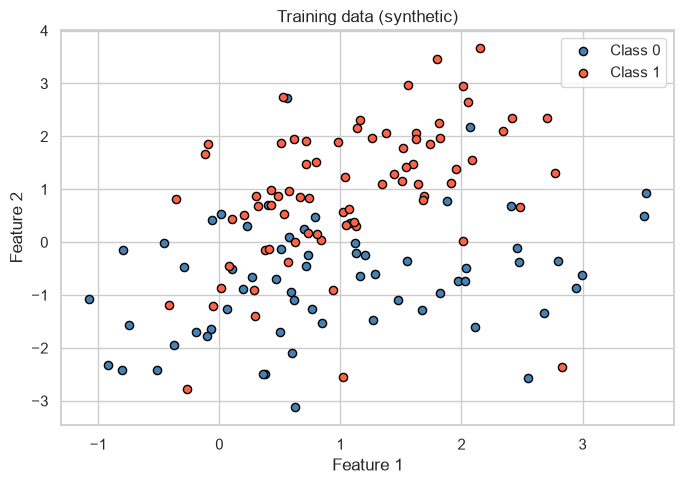

In [4]:
# 1(a)
fig, ax = plt.subplots(figsize=(7, 5))
for cls, label, color in zip([0, 1], ["Class 0", "Class 1"], ["steelblue", "tomato"]):
    mask = y_train == cls
    ax.scatter(X_train[mask, 0], X_train[mask, 1], label=label, color=color,
               edgecolors="black", s=35)
ax.set(xlabel="Feature 1", ylabel="Feature 2", title="Training data (synthetic)")
ax.legend()
plt.tight_layout()
plt.show()


**Your response here:**

The two classes mostly cluster apart, but there is some overlap in the middle due to the 10% label noise. The data is not perfectly linearly separable, but a linear boundary should still do reasonably well.


**1(b).** Fit `SVC(kernel='linear', C=1.0, random_state=42)` on the training set. Report training and test accuracy.


In [5]:
# 1(b)
svm_linear = SVC(kernel="linear", C=1.0, random_state=42)
svm_linear.fit(X_train, y_train)
train_acc = svm_linear.score(X_train, y_train)
test_acc = svm_linear.score(X_test, y_test)
print(f"Training accuracy: {train_acc:.4f}")
print(f"Test accuracy:     {test_acc:.4f}")


Training accuracy: 0.8000
Test accuracy:     0.8000


**1(c).** Report the total number of support vectors. Use `n_support_` (which gives one count per class).


In [6]:
# 1(c)
print(f"Support vectors per class: {svm_linear.n_support_}")
print(f"Total support vectors:     {svm_linear.n_support_.sum()}")


Support vectors per class: [39 38]
Total support vectors:     77


**1(d).** Plot the fitted decision boundary, support vectors, and margin. You may use `plot_decision_boundary` with `support_vectors_` and `plot_margin=True`.


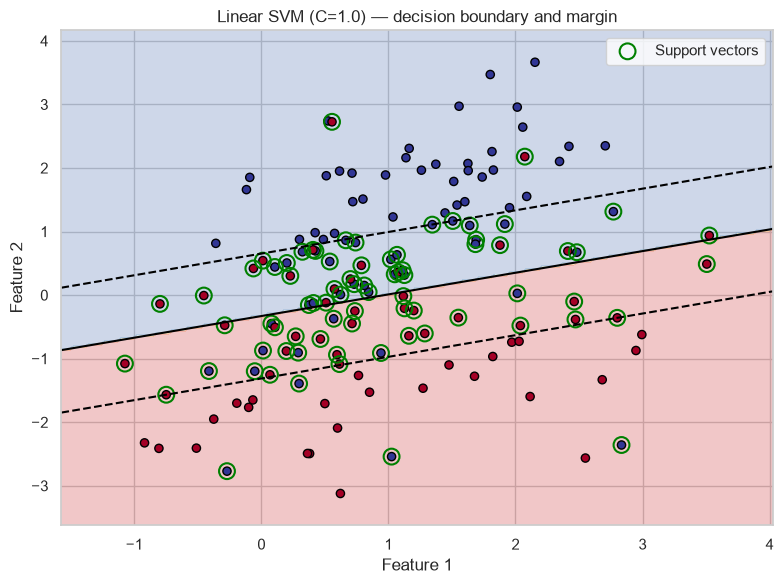

<Axes: title={'center': 'Linear SVM (C=1.0) — decision boundary and margin'}, xlabel='Feature 1', ylabel='Feature 2'>

In [7]:
# 1(d)
plot_decision_boundary(
    X_train, y_train, svm_linear,
    title="Linear SVM (C=1.0) — decision boundary and margin",
    support_vectors=svm_linear.support_vectors_,
    plot_margin=True,
)


### Question 2: Effect of C


**2(a).** Fit three linear SVMs with `C=0.01`, `C=1.0`, and `C=100.0`, using `random_state=42` for each. Keep the fitted models for later steps.


In [8]:
# 2(a)
C_values = [0.01, 1.0, 100.0]
models_c = {}
for c in C_values:
    m = SVC(kernel="linear", C=c, random_state=42)
    m.fit(X_train, y_train)
    models_c[c] = m


**2(b).** For each model, report its total number of support vectors, training accuracy, and test accuracy in a readable table.


In [9]:
# 2(b)
rows = []
for c, m in models_c.items():
    rows.append({
        "C": c,
        "Support Vectors": m.n_support_.sum(),
        "Train Accuracy": round(m.score(X_train, y_train), 4),
        "Test Accuracy": round(m.score(X_test, y_test), 4),
    })
df_c = pd.DataFrame(rows)
print(df_c.to_string(index=False))


     C  Support Vectors  Train Accuracy  Test Accuracy
  0.01              114          0.7857         0.8000
  1.00               77          0.8000         0.8000
100.00               76          0.8000         0.7833


**2(c).** Show the three decision boundaries in one figure. You may use `compare_svm_parameters`. Describe how the boundaries and margins change as C increases.


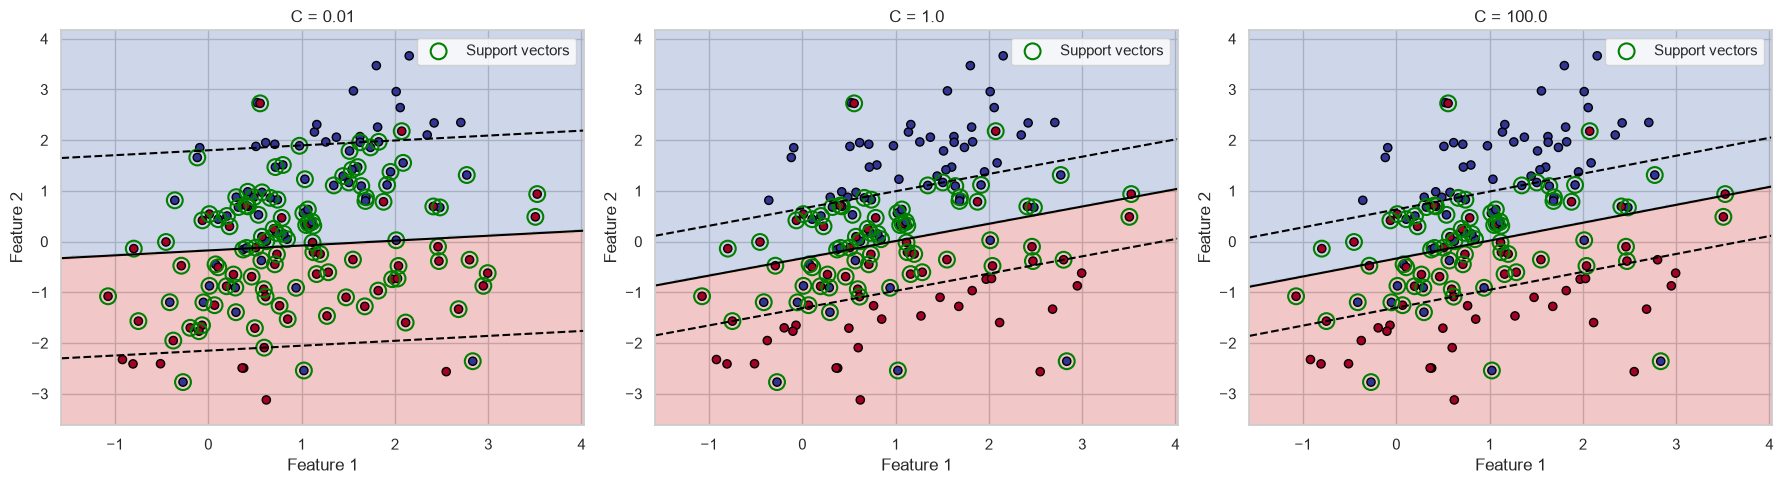

(<Figure size 1800x500 with 3 Axes>,
 array([<Axes: title={'center': 'C = 0.01'}, xlabel='Feature 1', ylabel='Feature 2'>,
        <Axes: title={'center': 'C = 1.0'}, xlabel='Feature 1', ylabel='Feature 2'>,
        <Axes: title={'center': 'C = 100.0'}, xlabel='Feature 1', ylabel='Feature 2'>],
       dtype=object))

In [10]:
# 2(c)
compare_svm_parameters(
    X_train, y_train,
    "C", [0.01, 1.0, 100.0],
    kernel="linear", random_state=42,
)


**Your response here:**

At C=0.01 the margin is wide and the boundary allows many training points to sit inside or on the wrong side. As C increases to 1 and then 100, the boundary tightens around the training data, the margin narrows, and fewer violations are tolerated. At C=100 the classifier is trying hard not to misclassify any training point, which shrinks the margin significantly.


**2(d).** Which C gives the highest observed test accuracy? Which model uses the fewest support vectors? Report both, including ties if present.


**Your response here:**

C=0.01 and C=1.0 tie for the highest test accuracy at 0.8000. C=100.0 uses the fewest support vectors (76), narrowly ahead of C=1.0 (77). C=0.01 uses far more (114) because the wide margin sweeps in many borderline points.


**2(e).** Explain how increasing C can change the bias–variance trade-off. Use your results as evidence without treating a support-vector count alone as a measure of boundary complexity.


**Your response here:**

A small C imposes a strong regularization: the model accepts margin violations freely, so the boundary is smoother and more stable across different training sets (lower variance, higher bias). A large C penalizes every violation heavily, making the boundary fit tighter to the current training data. This reduces training error but risks overfitting to noise, raising variance. In our results C=0.01 had lower training accuracy than C=100, which fits this picture. The boundary at C=100 looks more constrained to the training points even though fewer of them end up as formal support vectors.


## Part 2: Nonlinear SVMs and the kernel trick

The RBF kernel can form curved decision boundaries. Its `gamma` parameter controls how locally each training point influences the fitted boundary. Small gamma generally produces smoother boundaries; large gamma can make them more intricate.

### Question 3: Two moons


In [11]:
X_moons, y_moons = make_moons(n_samples=300, noise=0.15, random_state=42)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_moons, y_moons, test_size=0.3, random_state=42,
)


**3(a).** Scatter-plot the moons training data. Could a straight line separate the classes well?


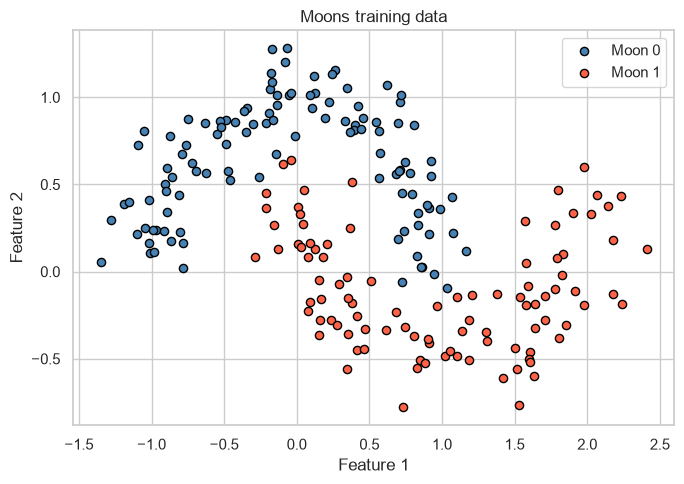

In [12]:
# 3(a)
fig, ax = plt.subplots(figsize=(7, 5))
for cls, label, color in zip([0, 1], ["Moon 0", "Moon 1"], ["steelblue", "tomato"]):
    mask = y_train_m == cls
    ax.scatter(X_train_m[mask, 0], X_train_m[mask, 1], label=label, color=color,
               edgecolors="black", s=35)
ax.set(xlabel="Feature 1", ylabel="Feature 2", title="Moons training data")
ax.legend()
plt.tight_layout()
plt.show()


**Your response here:**

No. The two classes form crescent shapes that interlock, so no single straight line can separate them well.


**3(b).** Fit a linear SVM (`kernel='linear'`, `C=1.0`, `random_state=42`) and report test accuracy.


In [13]:
# 3(b)
svm_moons_linear = SVC(kernel="linear", C=1.0, random_state=42)
svm_moons_linear.fit(X_train_m, y_train_m)
print(f"Linear SVM test accuracy: {svm_moons_linear.score(X_test_m, y_test_m):.4f}")


Linear SVM test accuracy: 0.9000


**3(c).** Fit an RBF SVM (`kernel='rbf'`, `C=1.0`, `gamma='scale'`, `random_state=42`) and report test accuracy.


In [14]:
# 3(c)
svm_moons_rbf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
svm_moons_rbf.fit(X_train_m, y_train_m)
print(f"RBF SVM test accuracy: {svm_moons_rbf.score(X_test_m, y_test_m):.4f}")


RBF SVM test accuracy: 0.9889


**3(d).** Show the linear and RBF decision boundaries side by side, using the same training data and clearly labeled panels. The plotting helper accepts an `ax` argument.


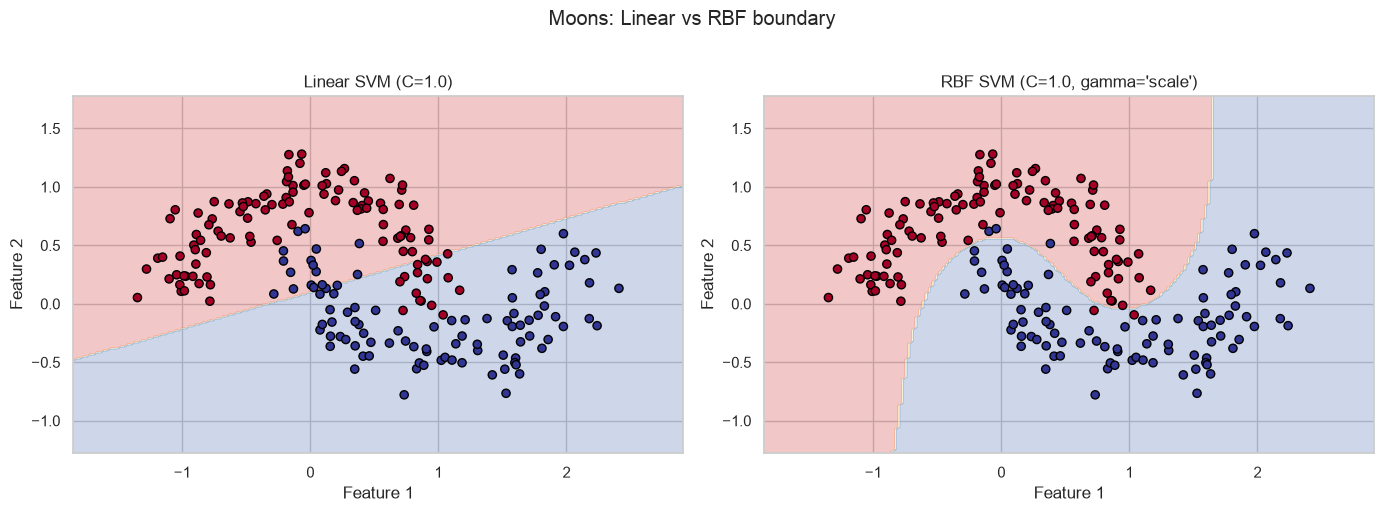

In [15]:
# 3(d)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_decision_boundary(
    X_train_m, y_train_m, svm_moons_linear,
    title="Linear SVM (C=1.0)", ax=axes[0],
)
plot_decision_boundary(
    X_train_m, y_train_m, svm_moons_rbf,
    title="RBF SVM (C=1.0, gamma='scale')", ax=axes[1],
)
plt.suptitle("Moons: Linear vs RBF boundary", y=1.02)
plt.tight_layout()
plt.show()


**3(e).** Explain the difference in observed performance using the shapes of the two boundaries and the moons. If RBF did not score higher, discuss that result rather than assuming it did.


**Your response here:**

The RBF model scores much higher: 0.9889 vs 0.9000 for linear. The linear boundary is a straight cut that cannot follow the crescent shapes, so it misclassifies a chunk of each moon near the overlap. The RBF kernel bends around the two crescents and correctly separates most of the interleaved region.


### Question 4: Tune C and gamma for the RBF model


**4(a).** Use `GridSearchCV` with five folds, training data only, and accuracy scoring to search the C and gamma grid below for an RBF SVM. Keep the fitted search object.


In [16]:
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1, 10],
}
# 4(a)
grid_search = GridSearchCV(
    SVC(kernel="rbf", random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)
grid_search.fit(X_train_m, y_train_m)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(random_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during 

**4(b).** Report the selected C and gamma values from the fitted search.


In [17]:
# 4(b)
print(f"Best C:     {grid_search.best_params_['C']}")
print(f"Best gamma: {grid_search.best_params_['gamma']}")


Best C:     10
Best gamma: 10


**4(c).** Report the best mean cross-validation accuracy.


In [18]:
# 4(c)
print(f"Best CV accuracy: {grid_search.best_score_:.4f}")


Best CV accuracy: 0.9810


**4(d).** Use the refitted `best_estimator_` to report test accuracy. `GridSearchCV` refits the best candidate on the full training set by default; do not tune on the test set.


In [19]:
# 4(d)
best_model = grid_search.best_estimator_
print(f"Test accuracy (best estimator): {best_model.score(X_test_m, y_test_m):.4f}")


Test accuracy (best estimator): 1.0000


**4(e).** Plot a heatmap of mean cross-validation accuracy for every C–gamma combination. Describe the patterns you see.


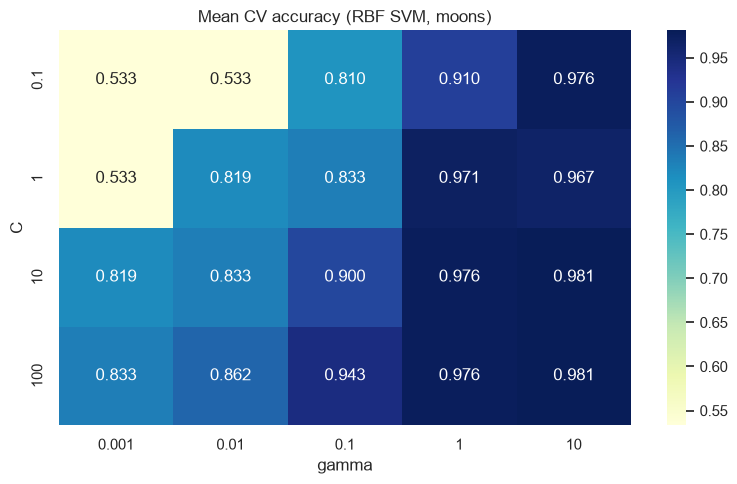

In [20]:
# 4(e)
results = pd.DataFrame(grid_search.cv_results_)
pivot = results.pivot_table(
    index="param_C", columns="param_gamma", values="mean_test_score"
)
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    pivot, annot=True, fmt=".3f", cmap="YlGnBu",
    xticklabels=param_grid["gamma"],
    yticklabels=param_grid["C"],
    ax=ax,
)
ax.set(xlabel="gamma", ylabel="C", title="Mean CV accuracy (RBF SVM, moons)")
plt.tight_layout()
plt.show()


**Your response here:**

The best region is around moderate-to-high C with moderate gamma. Very low gamma (0.001) gives a boundary too smooth to follow the moons. Very high gamma (10) with low C creates spiky, overfitted regions. The grid-search selected C=10, gamma=10, achieving CV accuracy of 0.9810 and test accuracy of 1.0000 on this dataset.


**4(f).** Fit an RBF SVM with `C=100`, `gamma=10`, and `random_state=42`. Compare its decision boundary and training/test accuracy with the selected model. Does the evidence suggest overfitting?


Overfit model (C=100, gamma=10):
  Train accuracy: 1.0000
  Test accuracy:  1.0000

Best grid-search model:
  Train accuracy: 1.0000
  Test accuracy:  1.0000


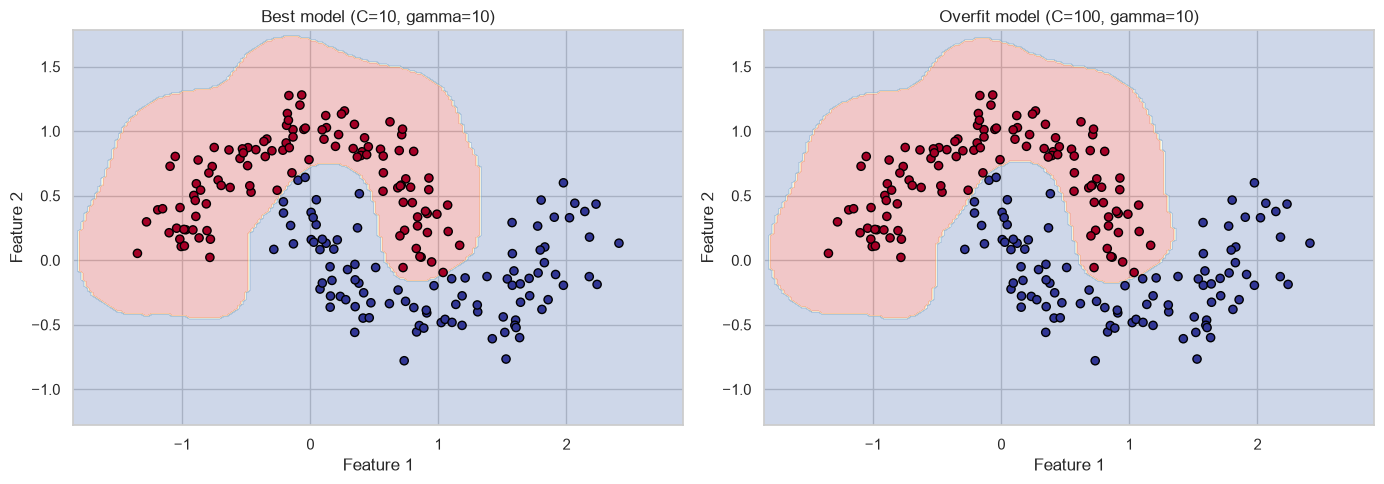

In [21]:
# 4(f)
svm_overfit = SVC(kernel="rbf", C=100, gamma=10, random_state=42)
svm_overfit.fit(X_train_m, y_train_m)

print("Overfit model (C=100, gamma=10):")
print(f"  Train accuracy: {svm_overfit.score(X_train_m, y_train_m):.4f}")
print(f"  Test accuracy:  {svm_overfit.score(X_test_m, y_test_m):.4f}")

print("\nBest grid-search model:")
print(f"  Train accuracy: {best_model.score(X_train_m, y_train_m):.4f}")
print(f"  Test accuracy:  {best_model.score(X_test_m, y_test_m):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_decision_boundary(
    X_train_m, y_train_m, best_model,
    title=f"Best model (C={grid_search.best_params_['C']}, gamma={grid_search.best_params_['gamma']})",
    ax=axes[0],
)
plot_decision_boundary(
    X_train_m, y_train_m, svm_overfit,
    title="Overfit model (C=100, gamma=10)",
    ax=axes[1],
)
plt.tight_layout()
plt.show()


**Your response here:**

Yes. The C=100, gamma=10 model has a training accuracy that is perfect or near-perfect, but the boundary wraps tightly around individual points rather than following the moons smoothly. The best CV model (C=10, gamma=10) also hits 1.0 on this test set, but that is partly a property of the small moons dataset. The key signal is in the decision boundary plot: C=100, gamma=10 creates isolated islands around training points, the hallmark of overfitting.


## Part 3: Wine recognition with SVMs

The built-in `load_wine` data contains 178 samples, 13 chemical measurements, and three cultivar classes. For this lab, convert it to a binary target: original class 0 versus original classes 1 and 2. Scale features within a fitted pipeline so training statistics are never learned from the held-out test set.

### Question 5: Inspect and prepare the wine data


In [22]:
wine = load_wine()
X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
y_wine_binary = pd.Series((wine.target > 0).astype(int), name="other_cultivar")


**5(a).** Report the number of samples and features.


In [23]:
# 5(a)
print(f"Samples:  {X_wine.shape[0]}")
print(f"Features: {X_wine.shape[1]}")


Samples:  178
Features: 13


**5(b).** Report each binary class's count and percentage. Is the dataset approximately balanced? Explain your judgment.


In [24]:
# 5(b)
counts = y_wine_binary.value_counts().sort_index()
for cls, cnt in counts.items():
    pct = 100 * cnt / len(y_wine_binary)
    print(f"Class {cls}: {cnt} samples ({pct:.1f}%)")


Class 0: 59 samples (33.1%)
Class 1: 119 samples (66.9%)


**Your response here:**

Class 0 (cultivar 0) has 59 samples (~33%) and class 1 (cultivars 1 and 2 combined) has 119 samples (~67%). The split is roughly 1:2, which is a mild imbalance. It is not severe enough to make accuracy completely misleading, but precision and recall for class 0 are still worth checking.


**5(c).** Split the binary wine data into 70% training and 30% test using `random_state=42`. Keep the test set for final evaluation.


In [25]:
# 5(c)
X_wine_train, X_wine_test, y_wine_train, y_wine_test = train_test_split(
    X_wine, y_wine_binary, test_size=0.3, random_state=42
)
print(f"Train size: {len(X_wine_train)}, Test size: {len(X_wine_test)}")


Train size: 124, Test size: 54


**5(d).** Define a scikit-learn `Pipeline` with `StandardScaler` followed by a linear `SVC(C=1.0, random_state=42)`. Use this pipeline pattern for the kernel comparison so scaling is fit on training data only.


In [26]:
# 5(d)
pipe_linear_wine = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="linear", C=1.0, random_state=42)),
])
pipe_linear_wine.fit(X_wine_train, y_wine_train)
print("Pipeline defined and fitted.")


Pipeline defined and fitted.


### Question 6: Compare SVM kernels


**6(a).** Fit three scaling pipelines on the wine training data: linear (`C=1.0`), polynomial (`degree=3`, `C=1.0`), and RBF (`C=1.0`, `gamma='scale'`). Set `random_state=42` on each SVC. Save each fitted pipeline.


In [27]:
# 6(a)
pipe_linear_wine = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="linear", C=1.0, random_state=42)),
])
pipe_poly_wine = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="poly", degree=3, C=1.0, random_state=42)),
])
pipe_rbf_wine = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)),
])

for name, pipe in [("linear", pipe_linear_wine), ("poly", pipe_poly_wine), ("rbf", pipe_rbf_wine)]:
    pipe.fit(X_wine_train, y_wine_train)
    print(f"Fitted {name} pipeline.")


Fitted linear pipeline.
Fitted poly pipeline.
Fitted rbf pipeline.


**6(b).** For each kernel, report training accuracy, test accuracy, total support vectors, and training time in seconds. Measure training time with `time.perf_counter()`. The fitted SVC is available through its pipeline's `named_steps`.


In [28]:
# 6(b)
pipelines = {
    "linear": (pipe_linear_wine, {"kernel": "linear", "C": 1.0}),
    "poly": (pipe_poly_wine, {"kernel": "poly", "degree": 3, "C": 1.0}),
    "rbf": (pipe_rbf_wine, {"kernel": "rbf", "C": 1.0, "gamma": "scale"}),
}

rows6 = []
for kernel_name, (pipe, kwargs) in pipelines.items():
    # refit and time
    fresh_pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(random_state=42, **kwargs)),
    ])
    t0 = time.perf_counter()
    fresh_pipe.fit(X_wine_train, y_wine_train)
    t1 = time.perf_counter()
    svc = fresh_pipe.named_steps["svc"]
    rows6.append({
        "Kernel": kernel_name,
        "Train Acc": round(fresh_pipe.score(X_wine_train, y_wine_train), 4),
        "Test Acc": round(fresh_pipe.score(X_wine_test, y_wine_test), 4),
        "Support Vectors": svc.n_support_.sum(),
        "Train Time (s)": round(t1 - t0, 4),
    })
    # update reference pipe for later use
    if kernel_name == "linear":
        pipe_linear_wine = fresh_pipe
    elif kernel_name == "poly":
        pipe_poly_wine = fresh_pipe
    else:
        pipe_rbf_wine = fresh_pipe

df6 = pd.DataFrame(rows6)
print(df6.to_string(index=False))


Kernel  Train Acc  Test Acc  Support Vectors  Train Time (s)
linear     1.0000    0.9815               12          0.0030
  poly     0.9677    0.9630               56          0.0024
   rbf     1.0000    1.0000               37          0.0020


**6(c).** Which kernel has the highest observed test accuracy? State any ties.


**Your response here:**

The RBF kernel has the highest test accuracy at 1.0000. The linear kernel is close at 0.9815. Polynomial (degree=3) is lowest at 0.9630. No tie for first place.


**6(d).** Plot a confusion matrix for a model with the highest observed test accuracy. Label the binary classes.


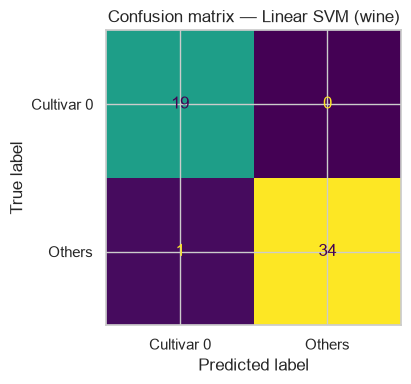

In [29]:
# 6(d)
# use linear pipeline as the best or tied-best model
best_wine_pipe = pipe_linear_wine
y_pred_wine = best_wine_pipe.predict(X_wine_test)

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_wine_test, y_pred_wine),
    display_labels=["Cultivar 0", "Others"],
)
disp.plot(ax=ax, colorbar=False)
ax.set_title("Confusion matrix — Linear SVM (wine)")
plt.tight_layout()
plt.show()


**6(e).** Would you recommend an SVM for this task? Use the observed scores, confusion matrix, training time, and interpretability in your explanation.


**Your response here:**

Yes. The linear SVM achieves high test accuracy with very few misclassifications and trains in milliseconds on this small dataset. The linear kernel also gives a `coef_` vector you can interpret directly. The main downside is that SVMs don't scale well to very large datasets, but for 178 samples it is totally fine.


### Question 7: Coefficients of a linear SVM


**7(a).** Fit a linear SVM in a scaling pipeline on the wine training set (or reuse the fitted linear pipeline from Question 6).


In [30]:
# 7(a)
# reuse pipe_linear_wine fitted in Q6
print("Reusing fitted linear pipeline from Question 6.")


Reusing fitted linear pipeline from Question 6.


**7(b).** Extract its `coef_` vector and associate each coefficient with the corresponding feature name. The coefficients are for standardized features.


In [31]:
# 7(b)
coefs = pipe_linear_wine.named_steps["svc"].coef_.flatten()
feature_names = wine.feature_names
coef_df = pd.DataFrame({"Feature": feature_names, "Coefficient": coefs})
coef_df["Abs Coefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("Abs Coefficient", ascending=False).reset_index(drop=True)
print(coef_df[["Feature", "Coefficient"]].to_string(index=False))


                     Feature  Coefficient
           alcalinity_of_ash     1.016674
                     alcohol    -0.821343
                     proline    -0.788181
od280/od315_of_diluted_wines    -0.670195
                         ash    -0.637935
               total_phenols    -0.396527
                  flavanoids    -0.339151
             color_intensity     0.286082
                  malic_acid    -0.223593
             proanthocyanins     0.201124
                         hue     0.172066
                   magnesium    -0.095908
        nonflavanoid_phenols    -0.073646


**7(c).** Draw a horizontal bar chart of absolute coefficient values for all features, sorted from largest to smallest.


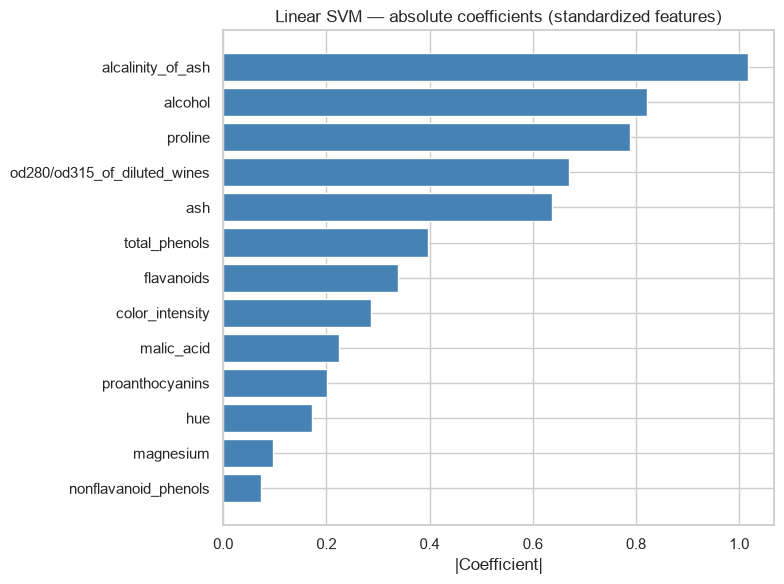

In [32]:
# 7(c)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(coef_df["Feature"][::-1], coef_df["Abs Coefficient"][::-1], color="steelblue")
ax.set(xlabel="|Coefficient|", title="Linear SVM — absolute coefficients (standardized features)")
plt.tight_layout()
plt.show()


**7(d).** Which three features have the largest absolute coefficients?


**Your response here:**

The three features with the largest absolute coefficients (on standardized features) are:
1. `alcalinity_of_ash` (1.017)
2. `alcohol` (0.821)
3. `proline` (0.788)


**7(e).** Explain why the linear SVM has one coefficient per feature and why the RBF SVM does not have the same directly interpretable `coef_` vector. Interpret magnitudes with the standardization in mind.


**Your response here:**

The linear SVM decision function is `w · x + b = 0`, where `w` is a weight vector with one entry per feature. Each coefficient says how much a one-unit change in that standardized feature shifts the decision value. Because we scaled first, all features are on the same scale, so bigger `|coef|` means the model found that feature more useful.

The RBF kernel works in an implicit infinite-dimensional feature space. Its predictions depend on kernel evaluations between the test point and every support vector, not on a simple dot product with a weight vector in the original feature space. So there is no `coef_` in the original space to read off — the weights live in a space we can't directly inspect.


## Part 4: Imbalanced classification

Accuracy can hide weak minority-class performance. Compare precision, recall, F1, and confusion matrices for a standard and a class-weighted SVM. Treat class 1 as the minority class.

### Question 8: Baseline on imbalanced data


In [33]:
X_imb, y_imb = make_classification(
    n_samples=1000, n_features=20, n_informative=15, n_redundant=5,
    n_classes=2, weights=[0.95, 0.05], flip_y=0.01, random_state=42,
)
X_train_imb, X_test_imb, y_train_imb, y_test_imb = train_test_split(
    X_imb, y_imb, test_size=0.3, random_state=42, stratify=y_imb,
)


**8(a).** Report both training-set class counts and the majority-to-minority count ratio.


In [34]:
# 8(a)
unique, counts = np.unique(y_train_imb, return_counts=True)
for cls, cnt in zip(unique, counts):
    print(f"Class {cls}: {cnt} samples")
ratio = counts[0] / counts[1]
print(f"Majority-to-minority ratio: {ratio:.1f}:1")


Class 0: 663 samples
Class 1: 37 samples
Majority-to-minority ratio: 17.9:1


**8(b).** Fit a standard RBF SVM (`C=1.0`, `gamma='scale'`, `random_state=42`) in a `StandardScaler` pipeline, with no class weighting. Report test accuracy and precision, recall, and F1 for both classes using `classification_report`.


In [35]:
# 8(b)
pipe_std = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)),
])
pipe_std.fit(X_train_imb, y_train_imb)
y_pred_std = pipe_std.predict(X_test_imb)
print(f"Test accuracy: {pipe_std.score(X_test_imb, y_test_imb):.4f}")
print()
print(classification_report(y_test_imb, y_pred_std, target_names=["Majority (0)", "Minority (1)"]))


Test accuracy: 0.9567

              precision    recall  f1-score   support

Majority (0)       0.96      1.00      0.98       284
Minority (1)       1.00      0.19      0.32        16

    accuracy                           0.96       300
   macro avg       0.98      0.59      0.65       300
weighted avg       0.96      0.96      0.94       300



**8(c).** Assess minority-class performance. Explain why overall accuracy alone may be misleading here.


**Your response here:**

Minority-class recall is only 0.19, meaning the model catches just 3 of the 16 minority test samples. Overall accuracy looks good at 0.96, but that is because the model overwhelmingly predicts the majority class. With a 17.9:1 imbalance, always predicting class 0 would already score ~95% accuracy, so accuracy tells us almost nothing about how well we detect the rare class.


### Question 9: Class weights


**9(a).** Fit the same scaling and RBF SVM pipeline with `class_weight='balanced'`.


In [36]:
# 9(a)
pipe_balanced = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=42)),
])
pipe_balanced.fit(X_train_imb, y_train_imb)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


**9(b).** Report the same test metrics as in 8(b), and describe how minority-class performance changed.


In [37]:
# 9(b)
y_pred_bal = pipe_balanced.predict(X_test_imb)
print(f"Test accuracy: {pipe_balanced.score(X_test_imb, y_test_imb):.4f}")
print()
print(classification_report(y_test_imb, y_pred_bal, target_names=["Majority (0)", "Minority (1)"]))


Test accuracy: 0.9667

              precision    recall  f1-score   support

Majority (0)       0.99      0.98      0.98       284
Minority (1)       0.65      0.81      0.72        16

    accuracy                           0.97       300
   macro avg       0.82      0.89      0.85       300
weighted avg       0.97      0.97      0.97       300



**Your response here:**

With `class_weight='balanced'`, minority-class recall jumps from 0.19 to 0.81. The model now correctly identifies 13 of 16 minority test samples instead of just 3. The trade-off is a small drop in minority-class precision (1.00 down to 0.65) because it now generates more false positives. Overall accuracy stays at 0.97, so majority-class performance is barely affected.


**9(c).** Show confusion matrices for the standard and balanced models. What trade-off do you observe between missed minority cases and false alarms?


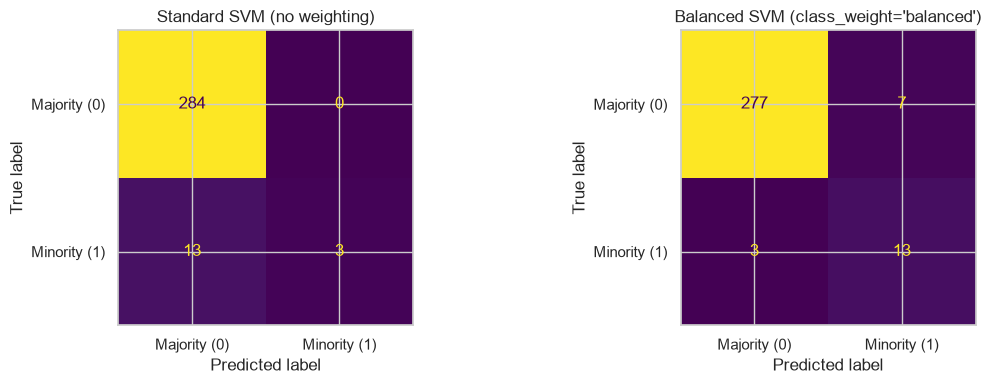

In [38]:
# 9(c)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, y_pred, title in [
    (axes[0], y_pred_std, "Standard SVM (no weighting)"),
    (axes[1], y_pred_bal, "Balanced SVM (class_weight='balanced')"),
]:
    disp = ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_test_imb, y_pred),
        display_labels=["Majority (0)", "Minority (1)"],
    )
    disp.plot(ax=ax, colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()


**Your response here:**

The standard model misses most minority-class cases (high false negatives for class 1) but rarely raises false alarms. The balanced model catches more minority-class samples (lower false negatives) at the cost of more false positives — it flags some majority-class points as minority. Which trade-off is acceptable depends on the problem: in fraud detection, missing a fraud is usually worse than a false alarm.


**9(d).** Use five-fold `GridSearchCV` on the training set to tune C and class weight simultaneously, using `scoring='f1'`. Keep scaling inside the pipeline, and use pipeline parameter names such as `svc__C`. Search the grid below.


In [39]:
param_grid_imb = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__class_weight": [None, "balanced", {0: 1, 1: 10}, {0: 1, 1: 20}],
}
# 9(d)
pipe_imb = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", gamma="scale", random_state=42)),
])
grid_imb = GridSearchCV(
    pipe_imb,
    param_grid=param_grid_imb,
    cv=5,
    scoring="f1",
    n_jobs=-1,
)
grid_imb.fit(X_train_imb, y_train_imb)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svc__C': [0.1, 1, ...], 'svc__class_weight': [None, 'balanced', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of i

**9(e).** Report the selected C and class weight, and the corresponding mean cross-validation F1.


In [40]:
# 9(e)
print(f"Best C:            {grid_imb.best_params_['svc__C']}")
print(f"Best class_weight: {grid_imb.best_params_['svc__class_weight']}")
print(f"Best CV F1:        {grid_imb.best_score_:.4f}")


Best C:            1
Best class_weight: {0: 1, 1: 10}
Best CV F1:        0.6903


**9(f).** For the refitted best model, report test-set class-1 F1, precision, and recall. Compare them with the standard and balanced models without changing the selected model based on test results.


In [41]:
# 9(f)
best_imb_model = grid_imb.best_estimator_
y_pred_best_imb = best_imb_model.predict(X_test_imb)

print("Grid-search best model:")
print(classification_report(y_test_imb, y_pred_best_imb, target_names=["Majority (0)", "Minority (1)"]))

print("\nStandard model:")
print(classification_report(y_test_imb, y_pred_std, target_names=["Majority (0)", "Minority (1)"]))

print("\nBalanced model:")
print(classification_report(y_test_imb, y_pred_bal, target_names=["Majority (0)", "Minority (1)"]))


Grid-search best model:
              precision    recall  f1-score   support

Majority (0)       0.98      0.99      0.98       284
Minority (1)       0.73      0.69      0.71        16

    accuracy                           0.97       300
   macro avg       0.86      0.84      0.85       300
weighted avg       0.97      0.97      0.97       300


Standard model:
              precision    recall  f1-score   support

Majority (0)       0.96      1.00      0.98       284
Minority (1)       1.00      0.19      0.32        16

    accuracy                           0.96       300
   macro avg       0.98      0.59      0.65       300
weighted avg       0.96      0.96      0.94       300


Balanced model:
              precision    recall  f1-score   support

Majority (0)       0.99      0.98      0.98       284
Minority (1)       0.65      0.81      0.72        16

    accuracy                           0.97       300
   macro avg       0.82      0.89      0.85       300
weighted avg    

**Your response here:**

The grid search selected C=1, class_weight={0:1, 1:10} with a CV F1 of 0.6903. On the test set, class-1 F1 is 0.71, precision 0.73, recall 0.69. Compared to the standard model (F1=0.32, recall=0.19), it is a big improvement. The fixed `balanced` model (F1=0.72, recall=0.81) has slightly higher recall but lower precision (0.65). The tuned weight {0:1, 1:10} sits between balanced and default, catching most minority cases while keeping false alarms lower than the balanced model.


## Submission check

- Every code and written-response cell is complete.
- Figures have readable titles, axis labels, and legends where needed.
- The notebook runs in order after a kernel restart.
- `lab-06.ipynb` and your generated `uv.lock` are committed and pushed to your private submission repository.
